# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 5</span>

In [3]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math
from IPython.display import Image, display

# Metropolis Algorithm

The Metropolis algorithm is a method used to sample from a target distribution $p(x)$ in any dimension (even when the normalization constant is unknown). It builds a Markov chain whose stationary distribution coincides with $p(x)$. The sample follows the target distribution only in the limit of infinite steps ($n \to \infty$). We call the initial part the "equilibration phase": we let this part elapse without sampling, and only afterwards do we start collecting samples.

Suppose $x_1, x_2, \dots$ are the steps of a random walk. Each $x_i$ is a random variable with an associated probability distribution $d_1(x_1), d_2(x_2), \dots$. We wish that

$$
\lim_{n \to \infty} d_n(x) = p(x)
$$

The transition kernel of the chain is written as

$$
K(x|y) = T(x|y)\, A(x|y)
$$

where $T(x|y)$ is the trial (proposal) distribution — the probability of proposing $x$ as the next state given that we are currently at $y$ — and $A(x|y)$ is the acceptance probability, which tells us whether to accept or reject the proposed point.

## Detailed balance

A sufficient condition for $d_n \to p$ is that $K$ satisfies detailed balance:

$$
p(x)\,K(y|x) = p(y)\,K(x|y)
$$

Substituting $K = T \cdot A$ and rearranging:

$$
\frac{A(y|x)}{A(x|y)} = \frac{p(y)\,T(x|y)}{p(x)\,T(y|x)} \equiv \frac{1}{q(x|y)}
$$

A choice of $A$ that satisfies this identically is

$$
A(x|y) = \min\big[1,\, q(x|y)\big], \qquad q(x|y) = \frac{p(x)\,T(y|x)}{p(y)\,T(x|y)} \ge 0
$$

Symmetric case: if the proposal is symmetric, $T(x|y) = T(y|x)$, this reduces to

$$
q(x|y) = \frac{p(x)}{p(y)} \ge 0
$$

## The algorithm

The algorithm consists of iterating the following steps:

1. **Initialization.** Choose an arbitrary initial state $x_0$.
2. **Trial move.** Propose a new state $x'$ by sampling from $T(x'|x_0)$.
3. **Acceptance.** Evaluate
$$
s = q(x'|x_0), \qquad A = \min(1, s)
$$
   Generate a uniform random number $r \sim \mathcal{U}(0,1)$:
   - if $r \le A$, accept the move: the new state is $x'$;
   - if $r > A$, reject the move: the new state remains $x_0$ (it is re-counted as the next sample).
4. **Iteration.** Set $x_0$ to the new state and return to step 2.

## Equilibration phase

Since $d_n \to p$ only asymptotically, early states are biased toward the arbitrary starting point $x_0$. In practice, the chain is run for $N_{eq}$ steps (equilibration), which are discarded; sampling starts only from $x_{N_{eq}+1}$ onward.

*Theory and simulation of random phenomena* — E. Vitali, M. Motta, D. E. Galli.

---

# Exercise 05.1

## Result

The purpose of this exercise is to sample the quantum orbitals ($1s$ and $2p$) of the hydrogen atom, exploiting the Metropolis algorithm. For each orbital we tested two choices of the trial move $T(x'|x_n)$: first a step drawn from a uniform distribution, then a step drawn from a Gaussian distribution.

```cpp
x_new = x + rnd.Rannyu(-step_size, step_size);   // uniform proposal
x_new = x + rnd.Gauss(0, sigma);                 // Gaussian proposal
```

Both proposals are symmetric ($T(x'|x_n) = T(x_n|x')$), so the Metropolis acceptance probability reduces to

$$
A = \min\left[1,\ \frac{p(x')}{p(x_n)}\right]
$$

with no Metropolis–Hastings correction needed.

**Step size calibration**. The step size (`step_size` for the uniform case, $\sigma$ for the Gaussian case) was tuned separately for each orbital and each proposal, targeting an acceptance rate of about 50%, a common rule of thumb that balances exploration efficiency against correlation between successive samples.

**Equilibration**. Before starting to collect data, the system was equilibrated for 1000 steps, allowing the chain to lose memory of the (arbitrary) starting point and relax toward the stationary distribution $p(x)$.

**Warning on the initial point**. Care must be taken when choosing the starting point $x_0$: it must lie in a region where $p(x_0) \neq 0$, otherwise, the initial acceptance ratio $p(x')/p(x_0)$ is ill-defined (division by zero) and the chain cannot start moving. This is particularly relevant for the $2p$ orbital, whose density $\propto z^2 e^{-r/a_0}$ vanishes on the plane $z = 0$.



###  Simulation Parameters 

* **Total Monte Carlo Steps ($M$):** $5 \times 10^6$ 
* **Number of Blocks:** $150$ 

####  $1s$ Orbital (Uniform Transition)
* **Initial Position $(x, y, z)$:** $(0.5 \, a_0, \; 0.5 \, a_0, \; -0.5 \, a_0)$
* **Step Size (`step_size`):** $1.2 \, a_0$

####  $2p$ Orbital (Uniform Transition)
* **Initial Position $(x_2, y_2, z_2)$:** $(0.1 \, a_0, \; 0.4 \, a_0, \; -0.3 \, a_0)$
* **Step Size (`step_size2`):** $2.9 \, a_0$

####  $1s$ Orbital (Gaussian Transition)
* **Initial Position $(x, y, z)$:** $(0.3 \, a_0, \; 0.2 \, a_0, \; -0.3 \, a_0)$
* **Standard Deviation (`sigma`):** $0.8 \, a_0$

####  $2p$ Orbital (Gaussian Transition)
* **Initial Position $(x_2, y_2, z_2)$:** $(0.1 \, a_0, \; 0.4 \, a_0, \; -0.3 \, a_0)$
* **Standard Deviation (`sigma`):** $2.0 \, a_0$


## Graphs

The graphs below show, for each orbital, the behaviour of $\langle r \rangle$ as a function of the number of blocks (with the associated statistical uncertainty computed via data blocking), together with the 3-dimensional scatter plot of the sampled points $(x,y,z)$, which visualises the spatial shape of the orbital reproduced by the Metropolis algorithm. **Both sampling methods yield consistent results**.

 
## Bonus

In another file (Lecture_5_bonus.ipynb), following the same Metropolis sampling and data-blocking procedure, you can find the corresponding graphs and 3D scatter plots for higher-energy orbitals described by the quantum numbers $(3,2,0)$ and $(3,2,2)$ (corresponding to $3d$ states). These plots illustrate how the spatial probability distributions and radial expectations behave for more complex angular momentum states.


---

 **Exercise**
 
In quantum physics a **wave function**, $\Psi$, is a mathematical description of the state of a quantum system. The wave function is a complex-valued probability amplitude, and the probabilities for the possible results of measurements made on the system can be derived from it.

For now on, let's consider the simple case of a non-relativistic single particle, without spin, in three spatial dimensions. The state of such a particle is completely described by its wave function, $\Psi(\vec{r},t)$, where $\vec{r}$ is position and $t$ is time.

For one spinless particle, if the wave function is interpreted as a probability amplitude, the square modulus of the wave function, $|\Psi(\vec{r},t)|^2$, is interpreted as the probability density that the particle is at $\vec{r}$ at time $t$. Once we have a probability density, we can use Monte Carlo ...

#### Hydrogen atom
The wave functions of the eigenstates of an electron in a Hydrogen atom (this is the only atom for which the Schroedinger equation has been solved exactly) are expressed in terms of spherical harmonics and generalized Laguerre polynomials. It is convenient to use spherical coordinates, and the wave function can be separated into functions of each coordinate:

$$
\Psi_{n,l,m}(r,\theta,\phi)=
\sqrt{\left(\frac{2}{na_0}\right)^3 \frac{(n-l-1)!}{2n[(n+l)!]}}
e^{-r/na_0}\left(\frac{2r}{na_0}\right)^l L_{n-l-1}^{2l+1}\left(\frac{2r}{na_0}\right)
Y_l^m(\theta,\phi)
$$

where $a_0=4\pi\epsilon_0\hbar^2/m_e e^2=0.0529$ nm is the Bohr radius, $L_{n-l-1}^{2l+1}$ are the generalized Laguerre polynomials of degree $n-l-1$, $n=1,2,...$ is the principal quantum number, $l=0,1, ..., n-1$ the azimuthal quantum number, $m=-l, -l+1, ..., l-1, l$ the magnetic quantum number.

For example, the ground state wave function is:
$$
\Psi_{1,0,0}(r,\theta,\phi)=
\frac{a_0^{-3/2}}{\sqrt{\pi}} e^{-r/a_0} 
$$
whereas one of the three $2p$ excited state is:
$$
\Psi_{2,1,0}(r,\theta,\phi)=
\frac{a_0^{-5/2}}{8}\sqrt{\frac{2}{\pi}} r e^{-r/2a_0} \cos(\theta)
$$
<span style="color:blue">Expectation values for the radius turns out to be exactly:
$$
\left\langle r \right\rangle_{\Psi_{1,0,0}} = \frac{3}{2}a_0
\quad
\left\langle r \right\rangle_{\Psi_{2,1,0}} = 5 a_0
$$
</span>


### Exercise 05.1


Use the Metropolis algorithm to sample $|\Psi_{1,0,0}(x,y,z)|^2$ and $|\Psi_{2,1,0}(x,y,z)|^2$ **in Cartesian coordinates** using, initially, an uniform transition probability $T(\vec{x}|\vec{y})$. Use the sampled positions to estimate $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$. As usual, use data blocking and give an estimate of the statistical uncertainties.

<span style="color:red">Show a picture of your estimations of $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$</span> and their uncertainties with a large number of *throws* $M$ (e.g. $M\ge 10^6$) as a function of the number of blocks, $N$</font>.

- Use Bohr radius units, $a_0$ for distances
- Choose the step of the uniform transition probability $T(\vec{x}|\vec{y})$ in order to obtain 50% of acceptance in both cases
- Choose a reasonable starting point in the 3D space and equilibrate your sampling before to start measuring the radius. What do you observe when you start very far from the origin?
- How large should be the number of Monte Carlo Metropolis steps in each block?
- <span style="color:red">If you use a multivariate normal transition probability $T(\vec{x}|\vec{y})$, i.e. a Gaussian for each coordinate, your results for $\left\langle r \right\rangle_{\Psi_{1,0,0}}$ and $\left\langle r \right\rangle_{\Psi_{2,1,0}}$ are equivalent?</span>

---

# Uniform
In this section the trial move is generated by sampling from a Uniform  $T(x'|x_n)$  

##   $\langle r \rangle$ orbital 1s 
quantum numbers n=1 , l=0 , $m_l=0$

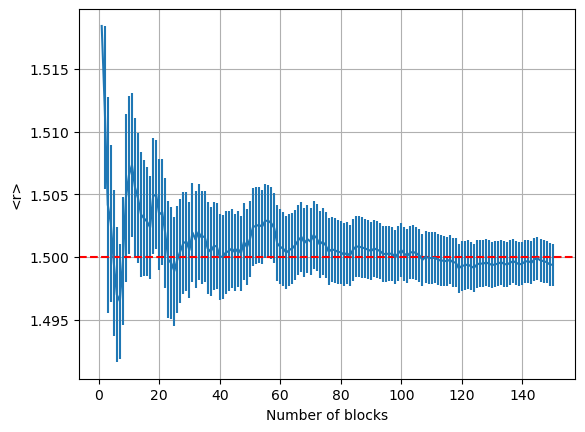

In [14]:
data = np.loadtxt("data_unif_r_1s.txt")

x = data[:,0]
mean = data[:,1]
err = data[:,2]

plt.errorbar(x, mean, yerr=err)

plt.axhline(
    y=1.5,
    color="r",
    linestyle="--",
    linewidth=1.5,
    label=r"Expected value ($3/2$)",
)

plt.xlabel("Number of blocks")
plt.ylabel("<r>")
plt.grid(True)

plt.show()

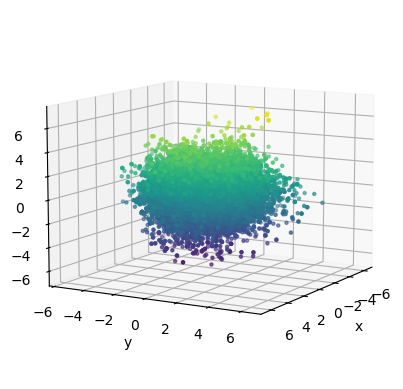

In [16]:
data3 = np.loadtxt("data_unif_xyz_1s.txt")
X=data3[:,0]
Y=data3[:,1]
Z=data3[:,2]

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X, Y, Z, c=Z, marker='.')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.view_init(10, 30)

plt.show()

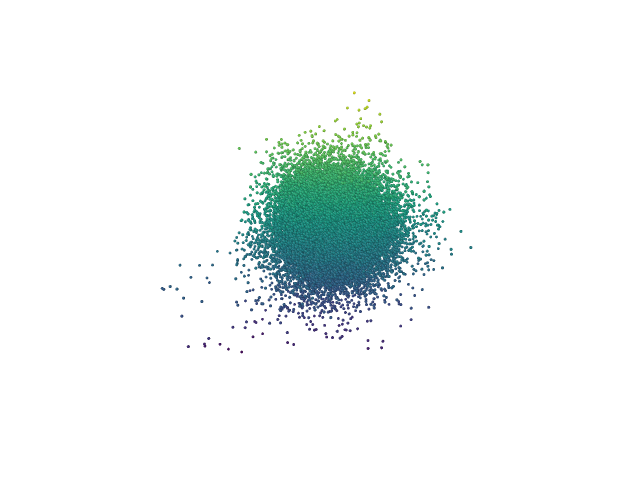

In [34]:
display(Image(filename='OVITO/Plot3D_1s.png', width=600))

##  $\langle r \rangle$ orbital 2p
quantum numbers n=2 , l=1 , $m_l=0$

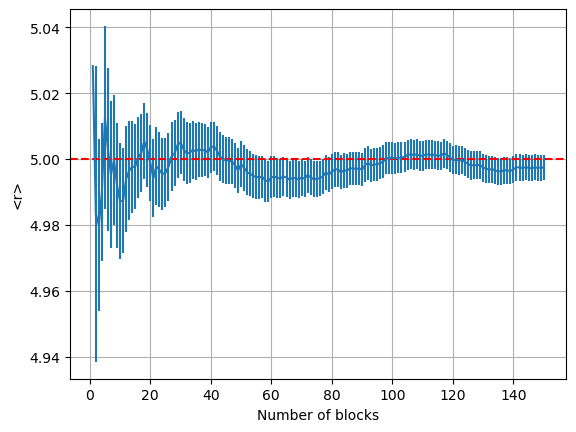

In [28]:
data2 = np.loadtxt("data_unif_r_2p.txt")

x = data2[:,0]
mean = data2[:,1]
err = data2[:,2]

plt.errorbar(x, mean, yerr=err)

plt.axhline(
    y=5,
    color="r",
    linestyle="--",
    linewidth=1.5,
    label=r"Expected value ($5$)",
)


plt.xlabel("Number of blocks")
plt.ylabel("<r>")
plt.grid(True)

plt.show()

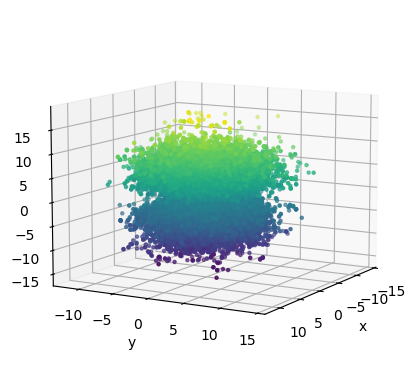

In [20]:
data4 = np.loadtxt("data_unif_xyz_2p.txt")
X=data4[:,0]
Y=data4[:,1]
Z=data4[:,2]

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X, Y, Z, c=Z, marker='.')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.view_init(10, 30)

plt.show()

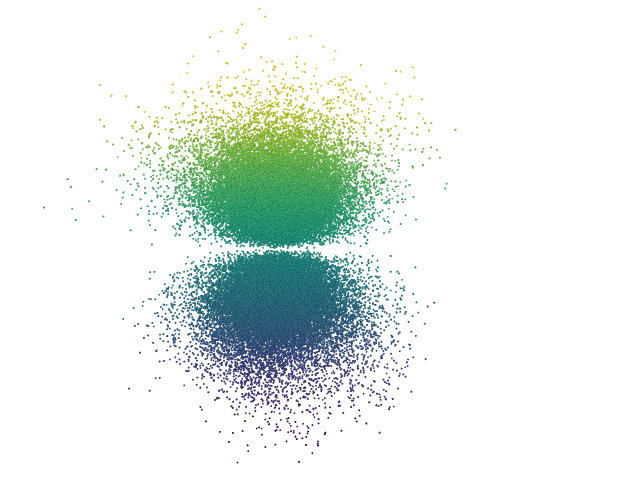

In [11]:

display(Image(filename='OVITO/Plot3D_2p.png', width=600))

---

# GAUSSIAN
In this section the trial move is generated by sampling from a Gaussian $T(x'|x_n)$ 

##   $\langle r \rangle$ orbital 1s
quatum numbers n=1 , l=0 , $m_l=0$

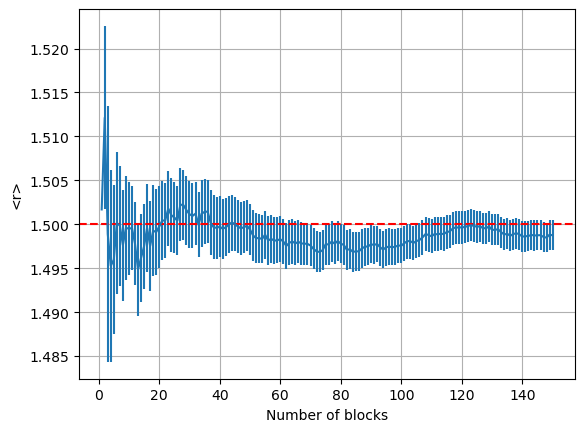

In [22]:
data = np.loadtxt("data_gauss_r_1s.txt")

x = data[:,0]
mean = data[:,1]
err = data[:,2]

plt.errorbar(x, mean, yerr=err)

plt.axhline(
    y=1.5,
    color="r",
    linestyle="--",
    linewidth=1.5,
    label=r"Expected value ($3/2$)",
)


plt.xlabel("Number of blocks")
plt.ylabel("<r>")
plt.grid(True)

plt.show()

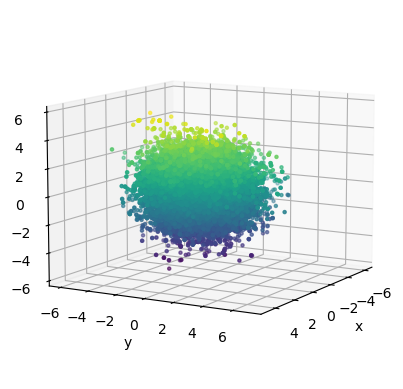

In [15]:
data3 = np.loadtxt("data_gauss_xyz_1s.txt")
X=data3[:,0]
Y=data3[:,1]
Z=data3[:,2]

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X, Y, Z, c=Z, marker='.')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.view_init(10, 30)

plt.show()

##  $\langle r \rangle$ orbital 2p
quantum numbers n=2 , l=1 , $m_l=0$

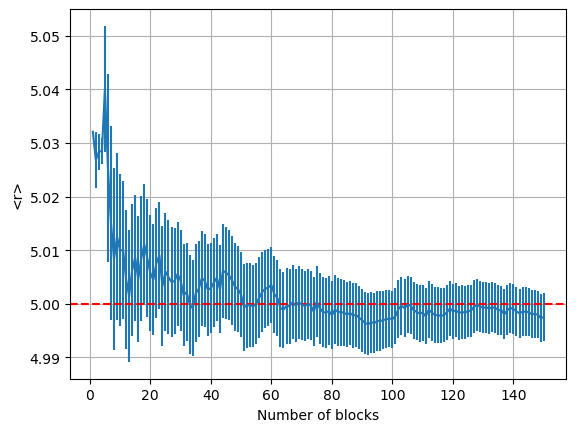

In [24]:
data2 = np.loadtxt("data_gauss_r_2p.txt")

x = data2[:,0]
mean = data2[:,1]
err = data2[:,2]

plt.errorbar(x, mean, yerr=err)

plt.axhline(
    y=5,
    color="r",
    linestyle="--",
    linewidth=1.5,
    label=r"Expected value ($5$)",
)


plt.xlabel("Number of blocks")
plt.ylabel("<r>")
plt.grid(True)

plt.show()

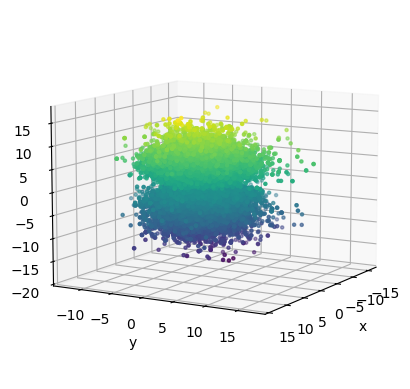

In [26]:
data3 = np.loadtxt("data_gauss_xyz_2p.txt")
X=data3[:,0]
Y=data3[:,1]
Z=data3[:,2]

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X, Y, Z, c=Z, marker='.')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.view_init(10, 30)

plt.show()